# Project setup

This notebook uses the shared functions in `visual_search/`. The dataset and generated feature caches stay outside GitHub.
If your Google Drive folder is different, edit `PROJECT_ROOT` and `DATASET_SOURCE` below.

In [ ]:
from pathlib import Path
import sys

# Mount Google Drive when this notebook is running in Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path("/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3")
DATASET_SOURCE = Path("/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2")

if not (PROJECT_ROOT / "cvpr").is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/ and visual_search/.")
if not (PROJECT_ROOT / "visual_search").is_dir():
    raise FileNotFoundError("The visual_search package is missing from PROJECT_ROOT.")

sys.path.insert(0, str(PROJECT_ROOT))
print("Project:", PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from cvpr.dataset import load_split_records, read_rgb
from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors
from cvpr.evaluation import evaluate_retrieval, per_category_summary
from cvpr.plotting import show_ranked_results

from visual_search.features import create_sift
from visual_search.cache import feature_cache_path, load_feature_cache

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, test = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)
assert (len(gallery), len(dev), len(test)) == (391, 100, 100)
print(f"Loaded {len(gallery)} gallery, {len(dev)} development and {len(test)} test images.")

Loaded 391 gallery, 100 development and 100 test images.


## 1. Run the supplied global-colour baseline

Each image is represented by a 4 × 4 × 4 RGB histogram. The resulting 64 values are compared using Euclidean distance.

In [ ]:
baseline_bins = 4
baseline_descriptor = lambda image: global_rgb_histogram(image, bins_per_channel=baseline_bins)

gallery_colour = compute_descriptors(gallery, baseline_descriptor)
dev_colour = compute_descriptors(dev, baseline_descriptor)

baseline_summary, baseline_rows = evaluate_retrieval(
    dev, dev_colour, gallery, gallery_colour, k=10
)
print(f"Development mAP: {baseline_summary['mAP']:.4f}")
print(f"Development mean P@10: {baseline_summary['mean_P@10']:.4f}")
print("Gallery feature matrix:", gallery_colour.shape)

Development mAP: 0.1592
Development mean P@10: 0.1830
Gallery feature matrix: (391, 64)


In [ ]:
# storing the per-group results so they can be compared with the BoVW methods later.
import csv

group_rows = per_category_summary(baseline_rows, k=10)
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(exist_ok=True)

with (results_dir / "baseline_dev_by_group.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=group_rows[0].keys())
    writer.writeheader()
    writer.writerows(group_rows)

with (results_dir / "baseline_dev_overall.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=baseline_summary.keys())
    writer.writeheader()
    writer.writerow(baseline_summary)

print("Saved baseline results to:", results_dir)

Saved baseline results to: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3/results


## 2. Inspect one baseline retrieval



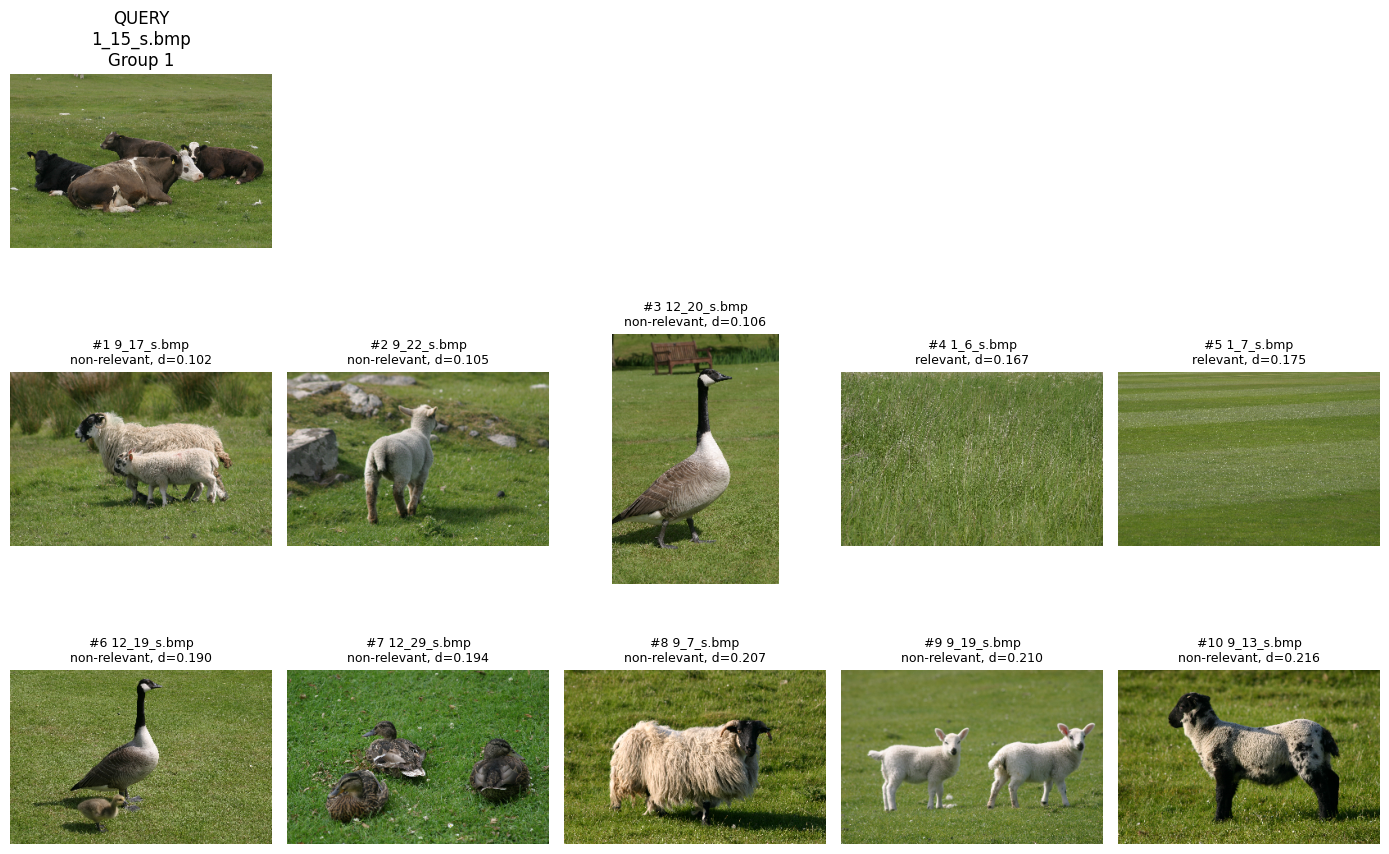

In [ ]:
query_index = 0
fig, ranked_indices = show_ranked_results(
    dev[query_index], dev_colour[query_index], gallery, gallery_colour, top_k=10
)
plt.show()

## 3. Extract and cache detected SIFT

OpenCV detects keypoints automatically. The cache stores the 128-dimensional descriptors and keypoint properties

In [ ]:
from visual_search.features import extract_detected_sift
from visual_search.cache import cache_gallery_features

DETECTED_CACHE = PROJECT_ROOT / "sift_cache" / "detected_sift"
sift = create_sift()

detected_counts = cache_gallery_features(
    gallery,
    DETECTED_CACHE,
    extractor=lambda image: extract_detected_sift(image, sift=sift),
    expected_dimension=128,
    rebuild=False,
)

print("Images cached:", len(detected_counts))
print("Images with zero keypoints:", int(np.sum(np.asarray(detected_counts) == 0)))

Processed 50/391 images
Processed 100/391 images
Processed 150/391 images
Processed 200/391 images
Processed 250/391 images
Processed 300/391 images
Processed 350/391 images
Processed 391/391 images
Images cached: 391
Images with zero keypoints: 0


Minimum: 3
Median: 432.0
Mean: 464.03
90th percentile: 776.0
Maximum: 1331


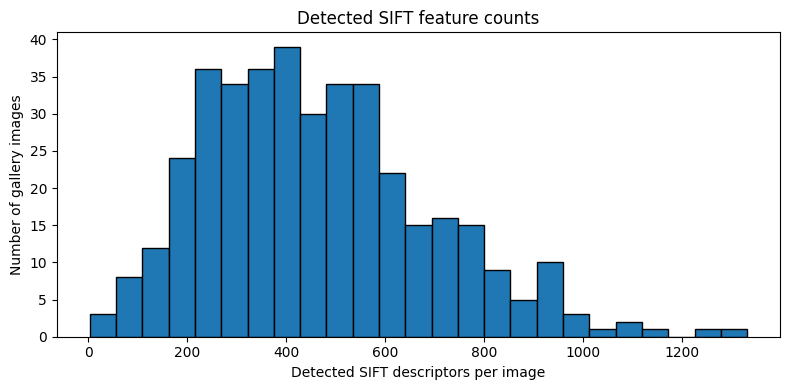

In [ ]:
# Summarise keypoint count overall and by filename-based retrieval group.
count_array = np.asarray(detected_counts)
print("Minimum:", int(count_array.min()))
print("Median:", float(np.median(count_array)))
print("Mean:", round(float(count_array.mean()), 2))
print("90th percentile:", float(np.percentile(count_array, 90)))
print("Maximum:", int(count_array.max()))

plt.figure(figsize=(8, 4))
plt.hist(count_array, bins=25, edgecolor="black")
plt.xlabel("Detected SIFT descriptors per image")
plt.ylabel("Number of gallery images")
plt.title("Detected SIFT feature counts")
plt.tight_layout()
plt.show()

group_summary = []
for group in sorted({record.category for record in gallery}):
    values = [count for record, count in zip(gallery, detected_counts) if record.category == group]
    group_summary.append({
        "group": group,
        "images": len(values),
        "mean_descriptors": float(np.mean(values)),
        "median_descriptors": float(np.median(values)),
    })

with (results_dir / "detected_sift_by_group.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=group_summary[0].keys())
    writer.writeheader()
    writer.writerows(group_summary)

## 4. Visual check

The three examples are selected by their detected descriptor count: few, around the median, and many.

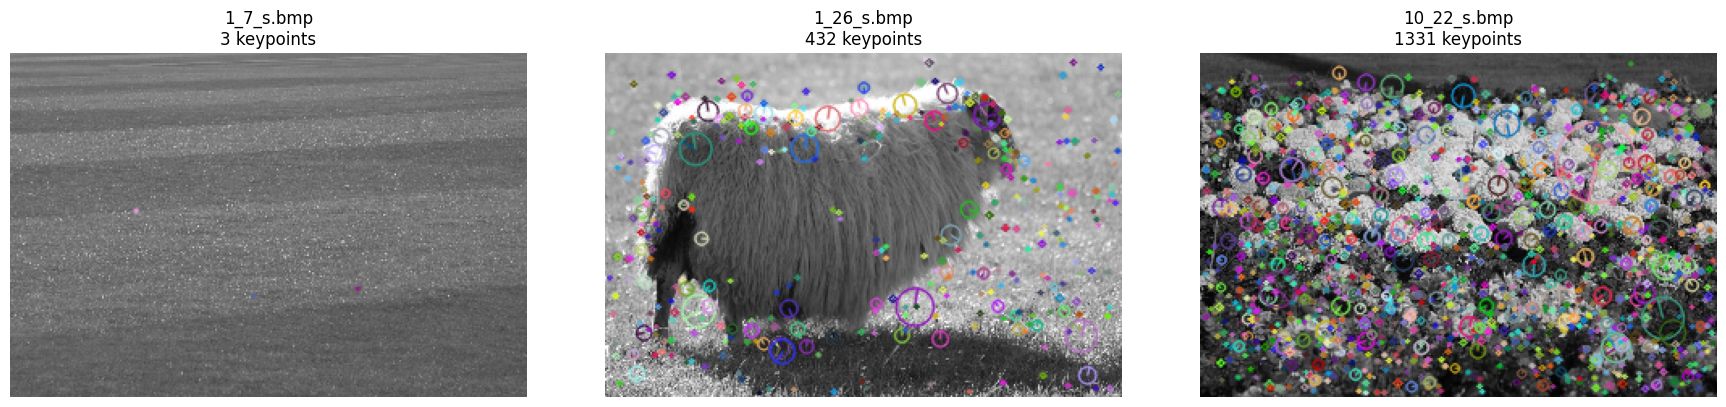

In [ ]:
counts = np.asarray(detected_counts)
example_indices = [int(np.argmin(counts)), int(np.argmin(np.abs(counts - np.median(counts)))), int(np.argmax(counts))]
example_indices = list(dict.fromkeys(example_indices))

sift = create_sift()
fig, axes = plt.subplots(1, len(example_indices), figsize=(6 * len(example_indices), 4))
if len(example_indices) == 1:
    axes = [axes]

for axis, index in zip(axes, example_indices):
    image = read_rgb(gallery[index].path)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    keypoints, _ = sift.detectAndCompute(gray, None)
    drawn = cv2.drawKeypoints(gray, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axis.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
    axis.set_title(f"{gallery[index].filename}\n{counts[index]} keypoints")
    axis.axis("off")

plt.tight_layout()
plt.show()